# Smart Twin — Predictive Maintenance EDA

## Exploratory Data Analysis of Synthetic Industrial Time-Series Data

This notebook performs a detailed exploratory analysis of the synthetic Smart Twin dataset.

### Project objective

We have multiple industrial machines observed over operating cycles. Each cycle contains sensor readings, degradation indicators, machine health information, failure status, and Remaining Useful Life (RUL).

The goal of this EDA is to understand:

- the structure of the machine fleet
- the time-series nature of the data
- sensor distributions and relationships
- degradation behavior
- machine health trends
- failure patterns and class balance
- RUL behavior
- potential data-quality problems
- potential data leakage
- which features are suitable for machine-learning models

**Important:** The dataset is synthetic/simulated. It is intended for developing and demonstrating the Smart Twin predictive-maintenance pipeline, not as real industrial measurements.


## 1. Imports and configuration

We will use:

- **Pandas / NumPy** for data manipulation
- **Matplotlib / Seaborn** for visualization
- **scikit-learn** for a few exploratory statistics and preprocessing checks


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load the combined dataset

The combined dataset contains all seven simulated machines.

Expected file:

```text
data/all_machines_combined.csv
```

If your notebook is stored in the project's `notebooks/` directory, the relative path below should work.


In [2]:
DATA_PATH = Path("../raw/all_machines_combined.csv")

df = pd.read_csv(DATA_PATH)

print(f"Loaded: {DATA_PATH}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")


Loaded: ../raw/all_machines_combined.csv
Rows: 1,930
Columns: 17


In [66]:
df.head()
df.columns


Index(['Machine_ID', 'Machine_Type', 'Failure_Mode', 'Cycle', 'Temperature_C',
       'Vibration_mm_s', 'Pressure_bar', 'Rotational_Speed_RPM',
       'Load_Fraction', 'Torque_Nm', 'Current_A', 'Acoustic_dB', 'Wear_Level',
       'Health_Index', 'Anomaly_Score', 'Failure', 'RUL_Cycles'],
      dtype='object')

## 3. Understand the dataset structure

First we inspect the dimensions, column names, data types, and a statistical summary.


In [4]:
print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:2}. {col}")


Dataset shape:
(1930, 17)

Column names:
 1. Machine_ID
 2. Machine_Type
 3. Failure_Mode
 4. Cycle
 5. Temperature_C
 6. Vibration_mm_s
 7. Pressure_bar
 8. Rotational_Speed_RPM
 9. Load_Fraction
10. Torque_Nm
11. Current_A
12. Acoustic_dB
13. Wear_Level
14. Health_Index
15. Anomaly_Score
16. Failure
17. RUL_Cycles


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1930 entries, 0 to 1929
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Machine_ID            1930 non-null   object 
 1   Machine_Type          1930 non-null   object 
 2   Failure_Mode          1930 non-null   object 
 3   Cycle                 1930 non-null   int64  
 4   Temperature_C         1930 non-null   float64
 5   Vibration_mm_s        1930 non-null   float64
 6   Pressure_bar          1930 non-null   float64
 7   Rotational_Speed_RPM  1930 non-null   float64
 8   Load_Fraction         1930 non-null   float64
 9   Torque_Nm             1930 non-null   float64
 10  Current_A             1930 non-null   float64
 11  Acoustic_dB           1930 non-null   float64
 12  Wear_Level            1930 non-null   float64
 13  Health_Index          1930 non-null   float64
 14  Anomaly_Score         1930 non-null   float64
 15  Failure              

In [6]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Machine_ID,1930,7,TURB_005,330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Machine_Type,1930,7,Turbine,330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Failure_Mode,1930,6,Bearing,590,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cycle,1930.0,NaN,NaN,NaN,140.53886,83.301714,1.0,69.25,138.0,207.0,330.0
Temperature_C,1930.0,NaN,NaN,NaN,74.197068,5.155292,64.641,70.3445,73.4915,77.342,93.677
Vibration_mm_s,1930.0,NaN,NaN,NaN,0.514481,0.270714,0.1243,0.285675,0.44515,0.693975,1.4827
Pressure_bar,1930.0,NaN,NaN,NaN,2.280856,0.146282,1.985,2.18,2.262,2.34775,2.991
Rotational_Speed_RPM,1930.0,NaN,NaN,NaN,1507.56929,24.454435,1423.63,1490.7525,1505.18,1526.2,1570.24
Load_Fraction,1930.0,NaN,NaN,NaN,0.686526,0.052026,0.524,0.65045,0.6869,0.722675,0.8213
Torque_Nm,1930.0,NaN,NaN,NaN,49.54446,2.147532,43.983,48.0215,49.3065,50.78175,59.477


## 4. Data-quality checks

We check for:

1. Missing values
2. Duplicate rows
3. Duplicate machine-cycle combinations
4. Invalid values
5. Constant columns


In [7]:
missing = df.isna().sum().sort_values(ascending=False)
missing_percent = (df.isna().mean() * 100).sort_values(ascending=False)

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percent": missing_percent.round(2)
})

missing_report


,Missing_Count,Missing_Percent
Machine_ID,0,0.0
Machine_Type,0,0.0
Failure_Mode,0,0.0
Cycle,0,0.0
Temperature_C,0,0.0
Vibration_mm_s,0,0.0
Pressure_bar,0,0.0
Rotational_Speed_RPM,0,0.0
Load_Fraction,0,0.0
Torque_Nm,0,0.0


In [8]:
print("Duplicate complete rows:", df.duplicated().sum())

duplicate_machine_cycles = df.duplicated(
    subset=["Machine_ID", "Cycle"]
).sum()

print("Duplicate Machine_ID + Cycle combinations:", duplicate_machine_cycles)


Duplicate complete rows: 0
Duplicate Machine_ID + Cycle combinations: 0


In [9]:
numeric_cols = df.select_dtypes(include=np.number).columns

constant_cols = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("Constant columns:", constant_cols if constant_cols else "None")


Constant columns: None


## 5. Machine fleet overview

A key property of our dataset is that the same machine appears across many cycles.

We therefore inspect:

- number of unique machines
- machine types
- failure modes
- number of cycles per machine


In [10]:
print("Number of unique machines:", df["Machine_ID"].nunique())

print("\nMachine IDs:")
print(df["Machine_ID"].unique())

print("\nMachine types:")
print(df[["Machine_ID", "Machine_Type"]].drop_duplicates().to_string(index=False))

print("\nFailure modes:")
print(df[["Machine_ID", "Failure_Mode"]].drop_duplicates().to_string(index=False))


Number of unique machines: 7

Machine IDs:
['CNC_001' 'PUMP_002' 'COMP_003' 'MOTOR_004' 'TURB_005' 'PRESS_006'
 'ROBOT_007']

Machine types:
Machine_ID     Machine_Type
   CNC_001         CNC_Mill
  PUMP_002   Hydraulic_Pump
  COMP_003       Compressor
 MOTOR_004   Electric_Motor
  TURB_005          Turbine
 PRESS_006  Hydraulic_Press
 ROBOT_007 Industrial_Robot

Failure modes:
Machine_ID Failure_Mode
   CNC_001      Bearing
  PUMP_002  Overheating
  COMP_003    Vibration
 MOTOR_004   Electrical
  TURB_005      Bearing
 PRESS_006     Pressure
 ROBOT_007     Actuator


In [11]:
cycles_per_machine = (
    df.groupby(["Machine_ID", "Machine_Type"])
      .agg(
          Observations=("Cycle", "size"),
          First_Cycle=("Cycle", "min"),
          Last_Cycle=("Cycle", "max"),
          Failure_Observations=("Failure", "sum")
      )
      .reset_index()
)

cycles_per_machine


,Machine_ID,Machine_Type,Observations,First_Cycle,Last_Cycle,Failure_Observations
0,CNC_001,CNC_Mill,260,1,260,17
1,COMP_003,Compressor,290,1,290,18
2,MOTOR_004,Electric_Motor,240,1,240,16
3,PRESS_006,Hydraulic_Press,275,1,275,17
4,PUMP_002,Hydraulic_Pump,310,1,310,19
5,ROBOT_007,Industrial_Robot,225,1,225,15
6,TURB_005,Turbine,330,1,330,20


### Cycles per machine

This is particularly important for a time-series predictive-maintenance problem because each machine should have a sequence of observations rather than isolated rows.


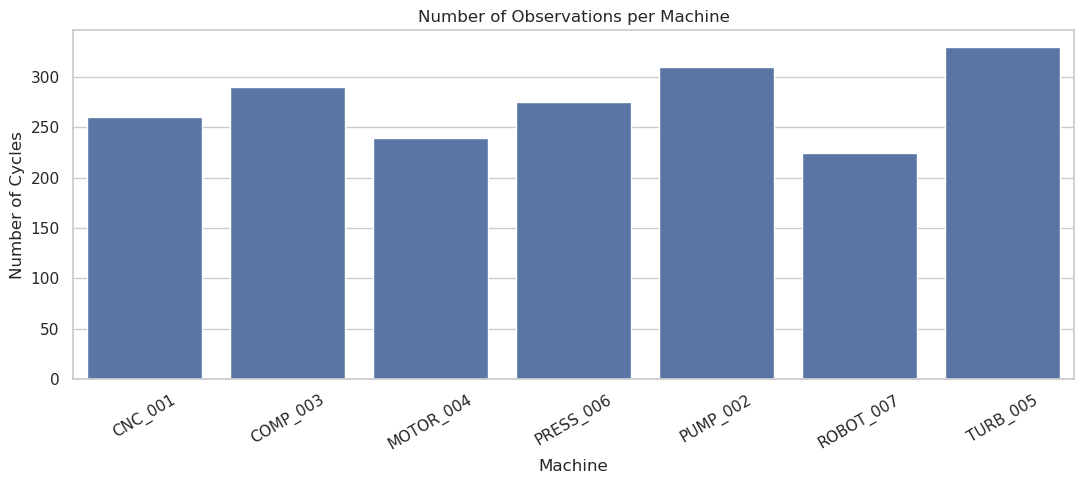

In [12]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=cycles_per_machine,
    x="Machine_ID",
    y="Observations"
)

plt.title("Number of Observations per Machine")
plt.xlabel("Machine")
plt.ylabel("Number of Cycles")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 6. Failure analysis

`Failure` is a binary target:

- `0` → machine is not in a failure state
- `1` → failure state

We first determine whether the target is balanced.


In [13]:
failure_counts = df["Failure"].value_counts().sort_index()

failure_summary = pd.DataFrame({
    "Count": failure_counts,
    "Percentage": (failure_counts / len(df) * 100).round(2)
})

failure_summary


,Count,Percentage
Failure,,
0,1808,93.68
1,122,6.32


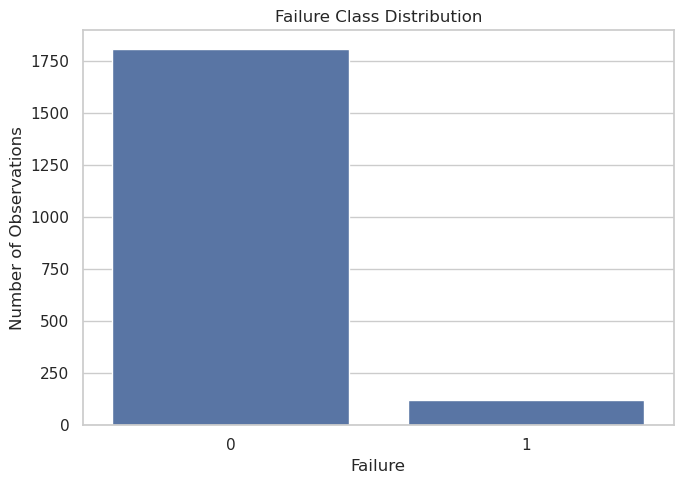

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Failure")

plt.title("Failure Class Distribution")
plt.xlabel("Failure")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()


### Failure distribution by machine

A machine-level view helps us determine whether failures are distributed similarly across the fleet.


In [15]:
failure_by_machine = (
    df.groupby("Machine_ID")["Failure"]
      .agg(["count", "sum"])
      .rename(columns={"count": "Total_Observations", "sum": "Failures"})
)

failure_by_machine["Failure_Rate_%"] = (
    failure_by_machine["Failures"] /
    failure_by_machine["Total_Observations"] * 100
).round(2)

failure_by_machine


,Total_Observations,Failures,Failure_Rate_%
Machine_ID,,,
CNC_001,260,17,6.54
COMP_003,290,18,6.21
MOTOR_004,240,16,6.67
PRESS_006,275,17,6.18
PUMP_002,310,19,6.13
ROBOT_007,225,15,6.67
TURB_005,330,20,6.06


## 7. Failure modes

Different machines in our simulation represent different degradation/failure mechanisms.

We inspect their distribution.


In [16]:
failure_mode_counts = df[["Machine_ID", "Failure_Mode"]].drop_duplicates()

failure_mode_counts


,Machine_ID,Failure_Mode
0,CNC_001,Bearing
260,PUMP_002,Overheating
570,COMP_003,Vibration
860,MOTOR_004,Electrical
1100,TURB_005,Bearing
1430,PRESS_006,Pressure
1705,ROBOT_007,Actuator


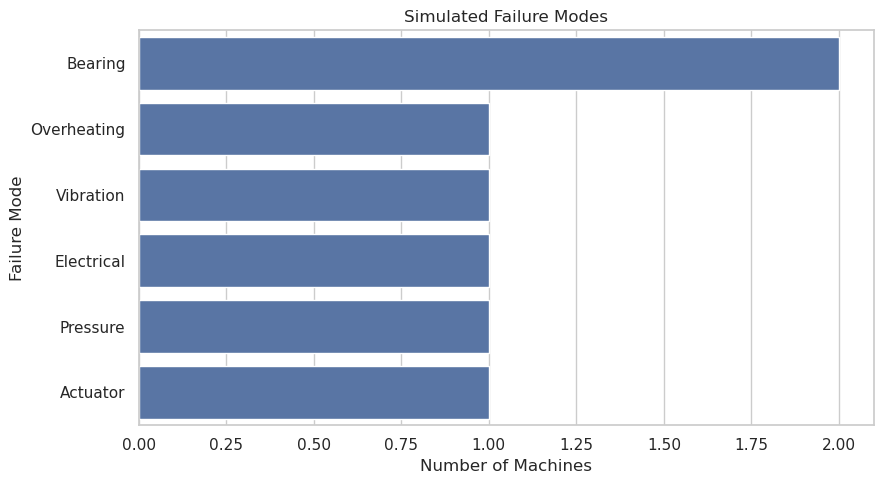

In [17]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=failure_mode_counts,
    y="Failure_Mode",
    order=failure_mode_counts["Failure_Mode"].value_counts().index
)

plt.title("Simulated Failure Modes")
plt.xlabel("Number of Machines")
plt.ylabel("Failure Mode")
plt.tight_layout()
plt.show()


## 8. RUL analysis

`RUL_Cycles` means **Remaining Useful Life in cycles**.

For a machine with 260 total cycles:

```text
Cycle 1   → RUL = 259
Cycle 100 → RUL = 160
Cycle 259 → RUL = 1
Cycle 260 → RUL = 0
```

RUL is especially useful for predictive maintenance because it answers a different question from binary failure prediction:

> "How long until the machine reaches its end of life?"


In [18]:
df["RUL_Cycles"].describe()


count    1930.000000
mean      139.538860
std        83.301714
min         0.000000
25%        68.250000
50%       137.000000
75%       206.000000
max       329.000000
Name: RUL_Cycles, dtype: float64

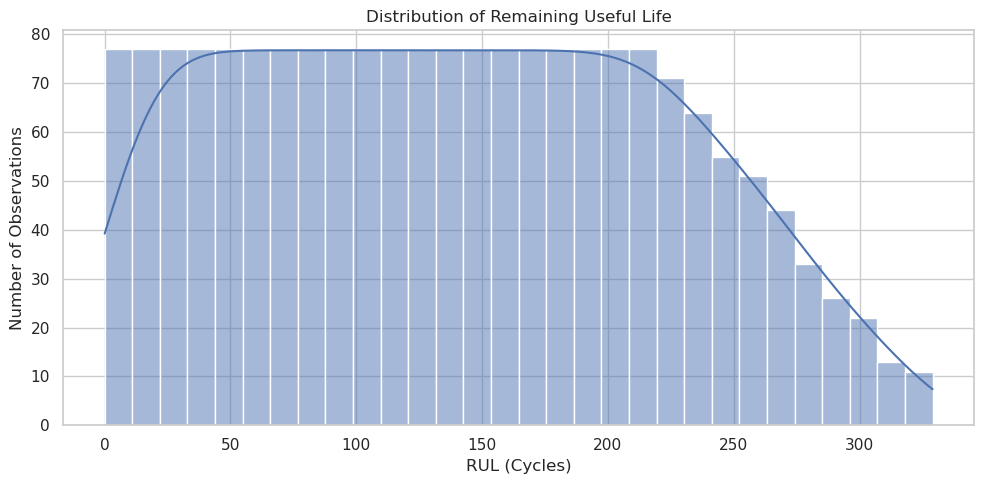

In [19]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="RUL_Cycles",
    bins=30,
    kde=True
)

plt.title("Distribution of Remaining Useful Life")
plt.xlabel("RUL (Cycles)")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()


## 9. RUL trajectories for every machine

Because this is time-series data, plotting RUL against cycle is one of the most important sanity checks.


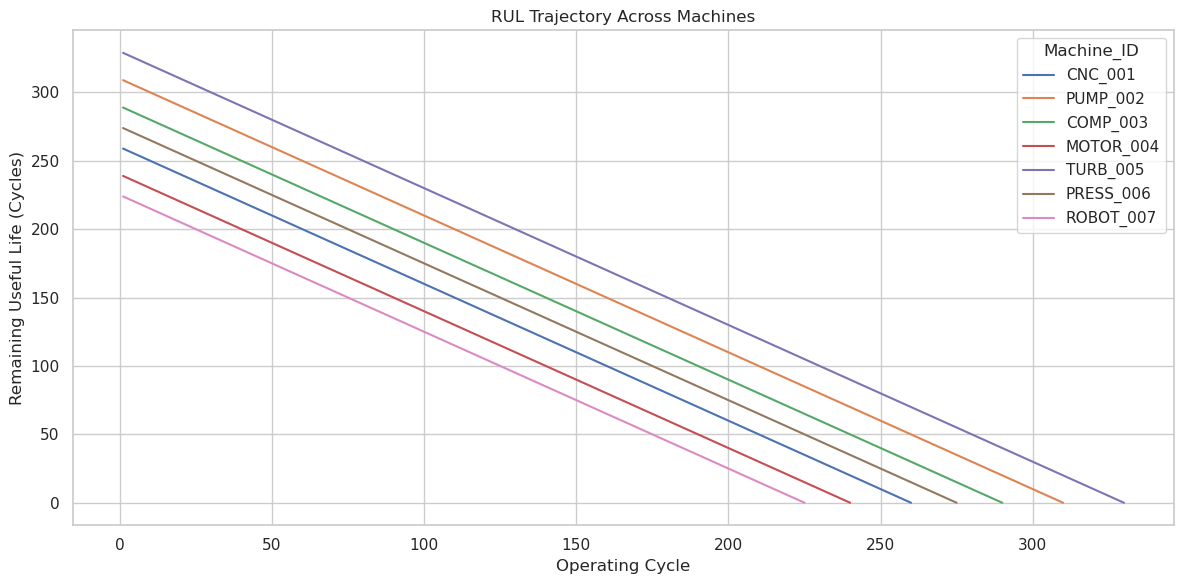

In [20]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x="Cycle",
    y="RUL_Cycles",
    hue="Machine_ID",
    marker=None
)

plt.title("RUL Trajectory Across Machines")
plt.xlabel("Operating Cycle")
plt.ylabel("Remaining Useful Life (Cycles)")
plt.tight_layout()
plt.show()


## 10. Machine health over time

`Health_Index` is a simulated health indicator where:

- values near 100 → healthier machine
- values near 0 → severely degraded machine

We expect health to decrease as the machine approaches failure.


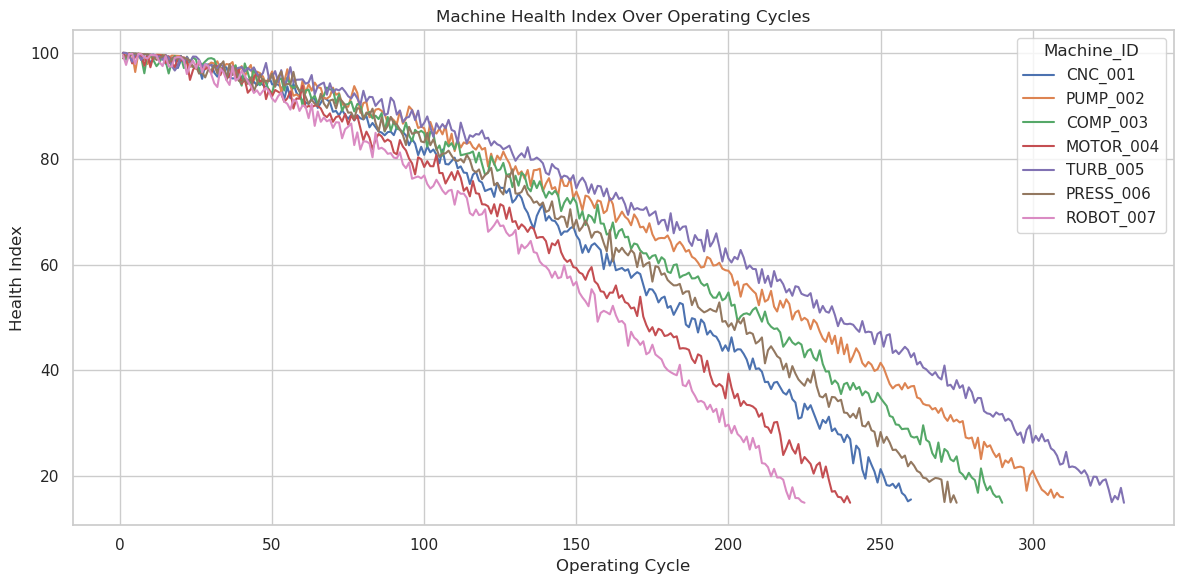

In [21]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x="Cycle",
    y="Health_Index",
    hue="Machine_ID"
)

plt.title("Machine Health Index Over Operating Cycles")
plt.xlabel("Operating Cycle")
plt.ylabel("Health Index")
plt.tight_layout()
plt.show()


## 11. Wear level over time

`Wear_Level` represents simulated accumulated degradation.

We expect it to increase with operating cycles.


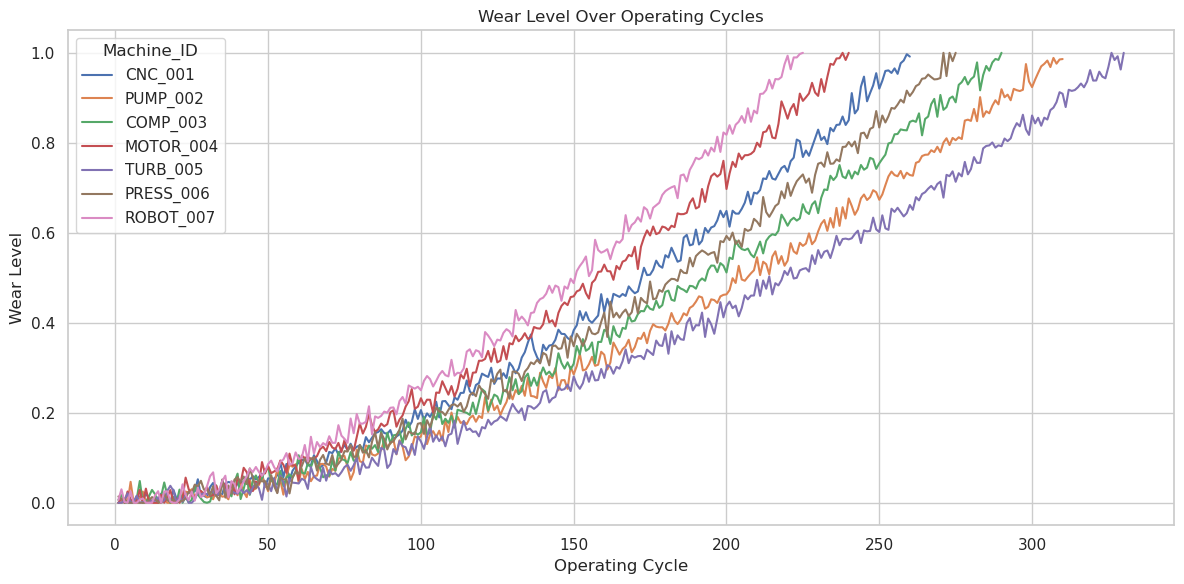

In [22]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x="Cycle",
    y="Wear_Level",
    hue="Machine_ID"
)

plt.title("Wear Level Over Operating Cycles")
plt.xlabel("Operating Cycle")
plt.ylabel("Wear Level")
plt.tight_layout()
plt.show()


## 12. Anomaly score over time

`Anomaly_Score` is a simulated indicator of increasingly abnormal machine behavior.

This can later be used by a Smart Twin layer as an early-warning signal.


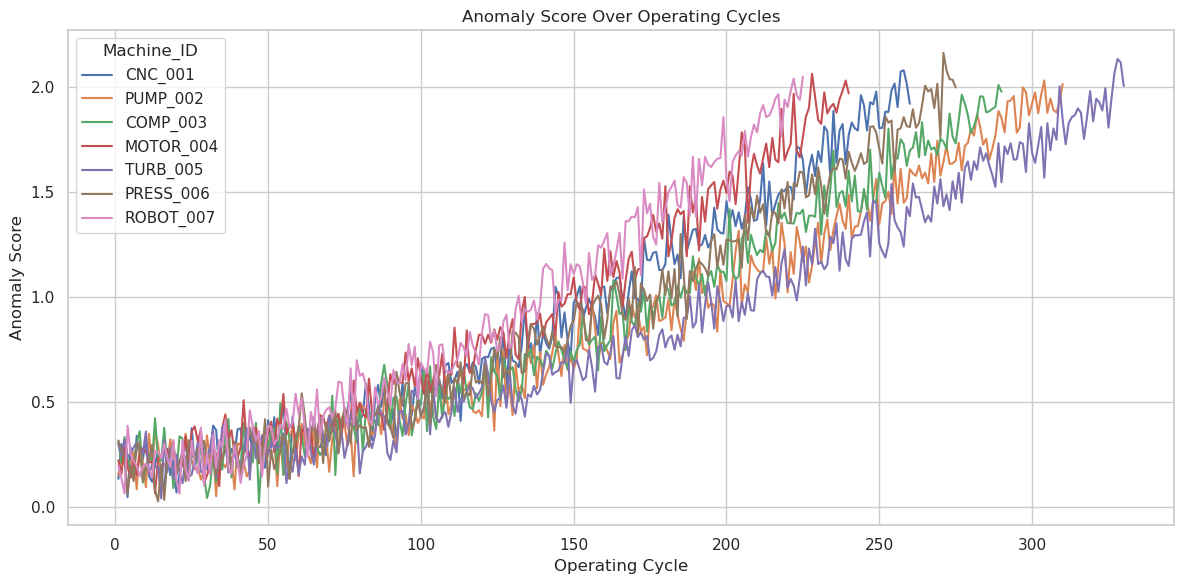

In [23]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x="Cycle",
    y="Anomaly_Score",
    hue="Machine_ID"
)

plt.title("Anomaly Score Over Operating Cycles")
plt.xlabel("Operating Cycle")
plt.ylabel("Anomaly Score")
plt.tight_layout()
plt.show()


## 13. Sensor distributions

Now we inspect the major sensor variables individually.

These are the variables we will potentially use as model features.


In [24]:
sensor_cols = [
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Rotational_Speed_RPM",
    "Load_Fraction",
    "Torque_Nm",
    "Current_A",
    "Acoustic_dB",
]

df[sensor_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
Temperature_C,1930.0,74.197068,5.155292,64.6410,70.344500,73.49150,77.342000,93.6770
Vibration_mm_s,1930.0,0.514481,0.270714,0.1243,0.285675,0.44515,0.693975,1.4827
Pressure_bar,1930.0,2.280856,0.146282,1.9850,2.180000,2.26200,2.347750,2.9910
Rotational_Speed_RPM,1930.0,1507.569290,24.454435,1423.6300,1490.752500,1505.18000,1526.200000,1570.2400
Load_Fraction,1930.0,0.686526,0.052026,0.5240,0.650450,0.68690,0.722675,0.8213
Torque_Nm,1930.0,49.544460,2.147532,43.9830,48.021500,49.30650,50.781750,59.4770
Current_A,1930.0,10.089839,0.703244,8.6500,9.578000,9.96400,10.481750,13.8780
Acoustic_dB,1930.0,61.312349,5.048952,52.0820,57.013500,60.44450,65.163500,76.8360


### Sensor histograms

Each sensor gets its own distribution plot so we can inspect skew, spread, and unusual values.


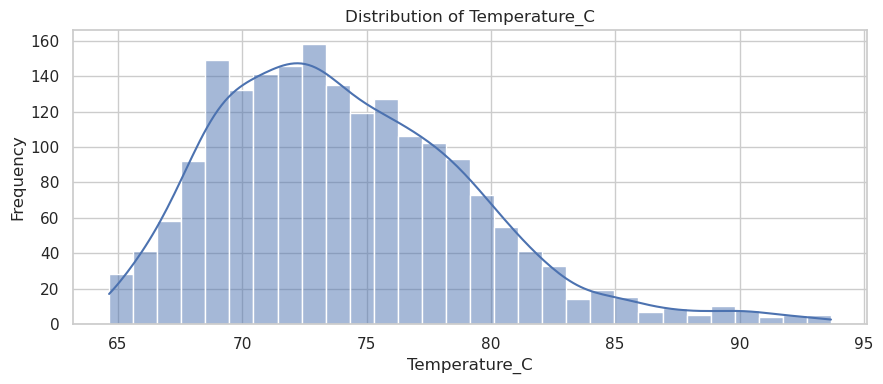

In [25]:
plt.figure(figsize=(9, 4))

sns.histplot(
    data=df,
    x="Temperature_C",
    bins=30,
    kde=True
)

plt.title("Distribution of Temperature_C")
plt.xlabel("Temperature_C")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


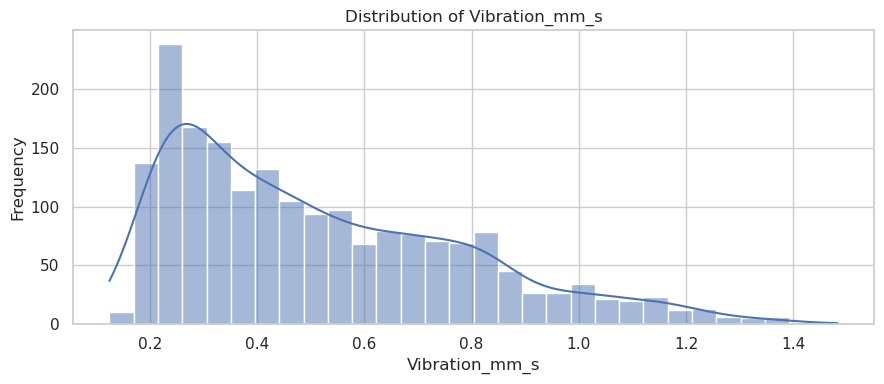

In [26]:
plt.figure(figsize=(9, 4))

sns.histplot(
    data=df,
    x="Vibration_mm_s",
    bins=30,
    kde=True
)

plt.title("Distribution of Vibration_mm_s")
plt.xlabel("Vibration_mm_s")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


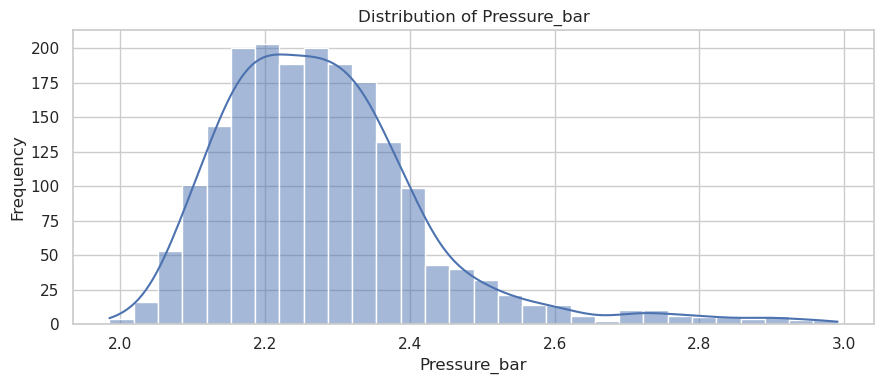

In [27]:
plt.figure(figsize=(9, 4))

sns.histplot(
    data=df,
    x="Pressure_bar",
    bins=30,
    kde=True
)

plt.title("Distribution of Pressure_bar")
plt.xlabel("Pressure_bar")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


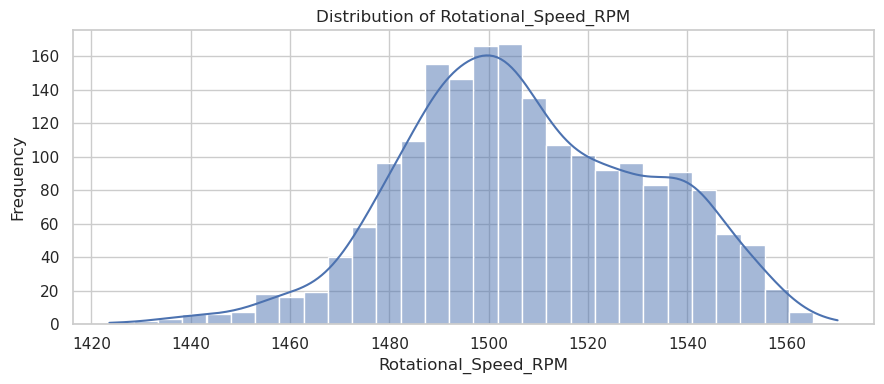

In [28]:
plt.figure(figsize=(9, 4))

sns.histplot(
    data=df,
    x="Rotational_Speed_RPM",
    bins=30,
    kde=True
)

plt.title("Distribution of Rotational_Speed_RPM")
plt.xlabel("Rotational_Speed_RPM")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


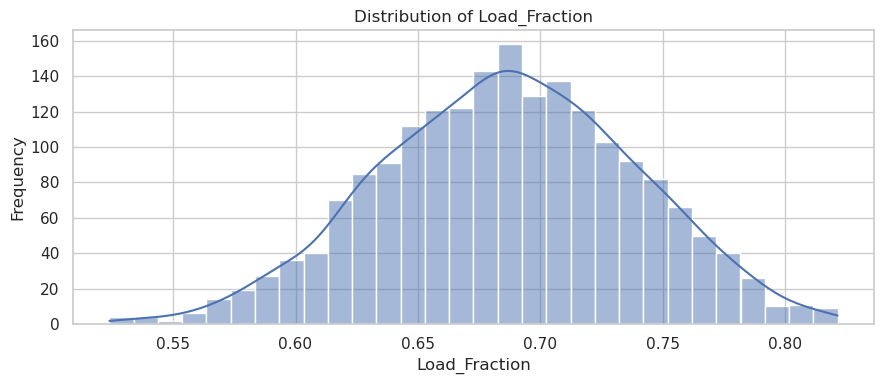

In [29]:
plt.figure(figsize=(9, 4))

sns.histplot(
    data=df,
    x="Load_Fraction",
    bins=30,
    kde=True
)

plt.title("Distribution of Load_Fraction")
plt.xlabel("Load_Fraction")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


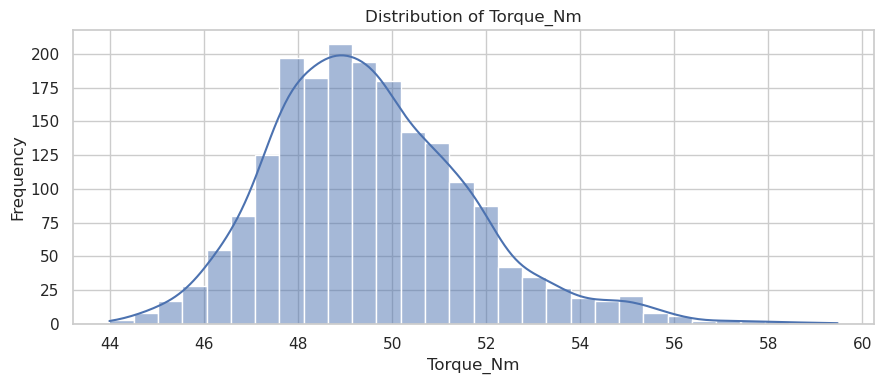

In [30]:
plt.figure(figsize=(9, 4))

sns.histplot(
    data=df,
    x="Torque_Nm",
    bins=30,
    kde=True
)

plt.title("Distribution of Torque_Nm")
plt.xlabel("Torque_Nm")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


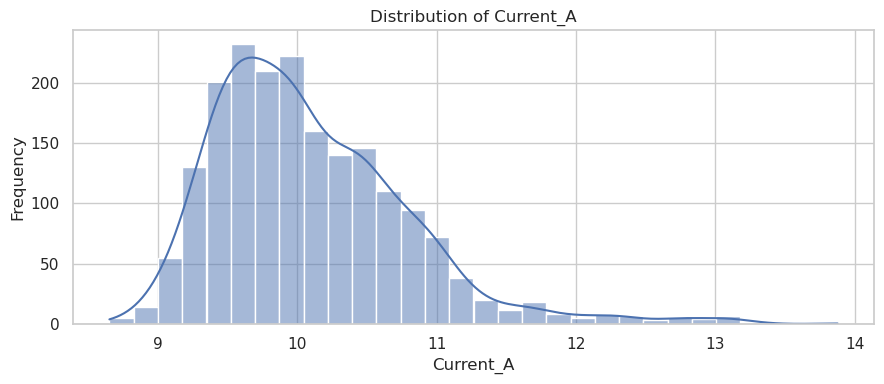

In [31]:
plt.figure(figsize=(9, 4))

sns.histplot(
    data=df,
    x="Current_A",
    bins=30,
    kde=True
)

plt.title("Distribution of Current_A")
plt.xlabel("Current_A")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


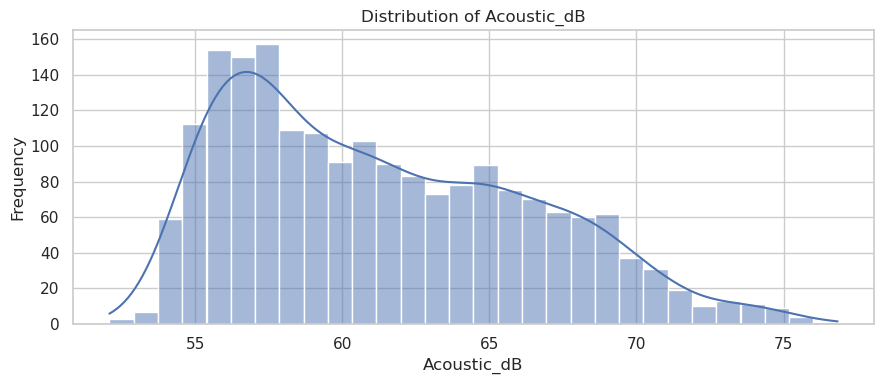

In [32]:
plt.figure(figsize=(9, 4))

sns.histplot(
    data=df,
    x="Acoustic_dB",
    bins=30,
    kde=True
)

plt.title("Distribution of Acoustic_dB")
plt.xlabel("Acoustic_dB")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## 14. Sensor behavior over time

A sensor that changes systematically with machine age can be useful for predictive maintenance.

We inspect each major sensor against operating cycle.


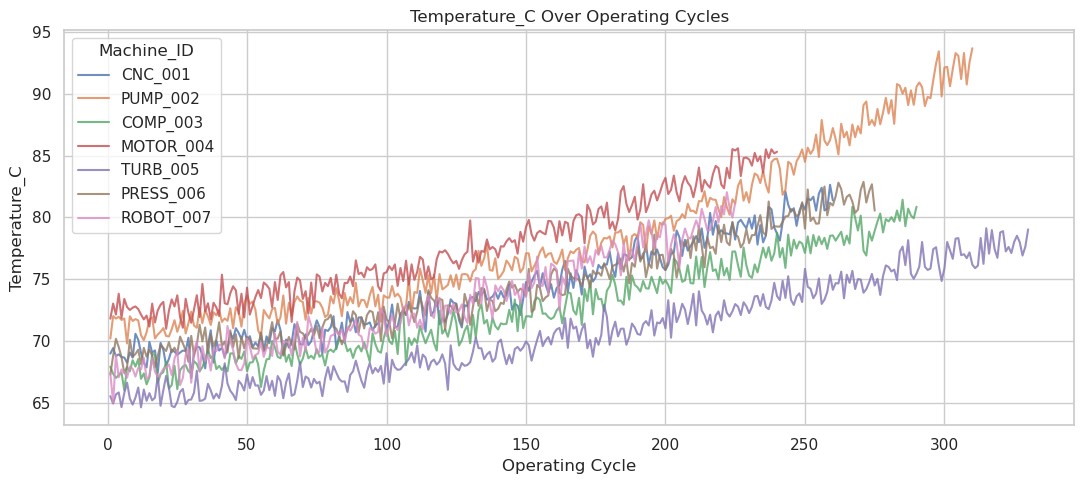

In [33]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=df,
    x="Cycle",
    y="Temperature_C",
    hue="Machine_ID",
    alpha=0.8
)

plt.title("Temperature_C Over Operating Cycles")
plt.xlabel("Operating Cycle")
plt.ylabel("Temperature_C")
plt.tight_layout()
plt.show()


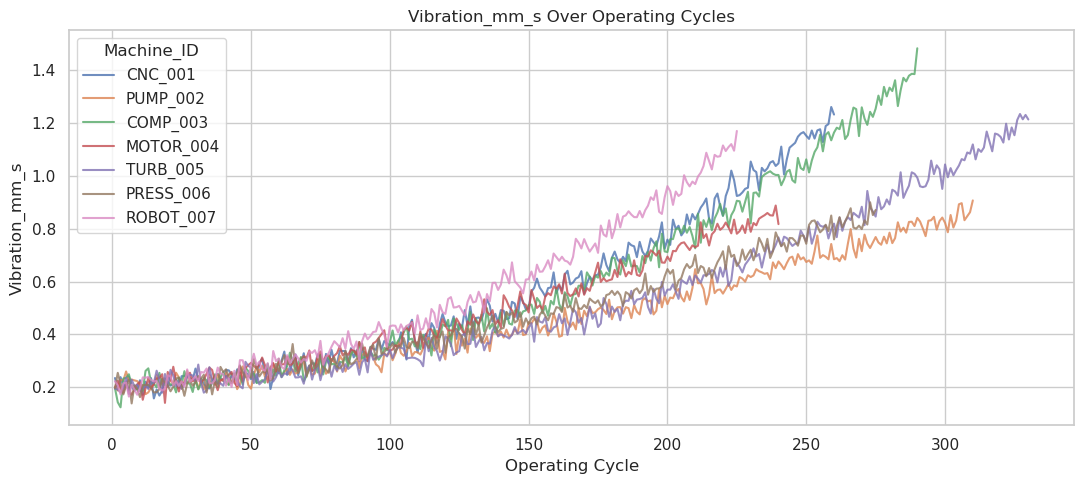

In [34]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=df,
    x="Cycle",
    y="Vibration_mm_s",
    hue="Machine_ID",
    alpha=0.8
)

plt.title("Vibration_mm_s Over Operating Cycles")
plt.xlabel("Operating Cycle")
plt.ylabel("Vibration_mm_s")
plt.tight_layout()
plt.show()


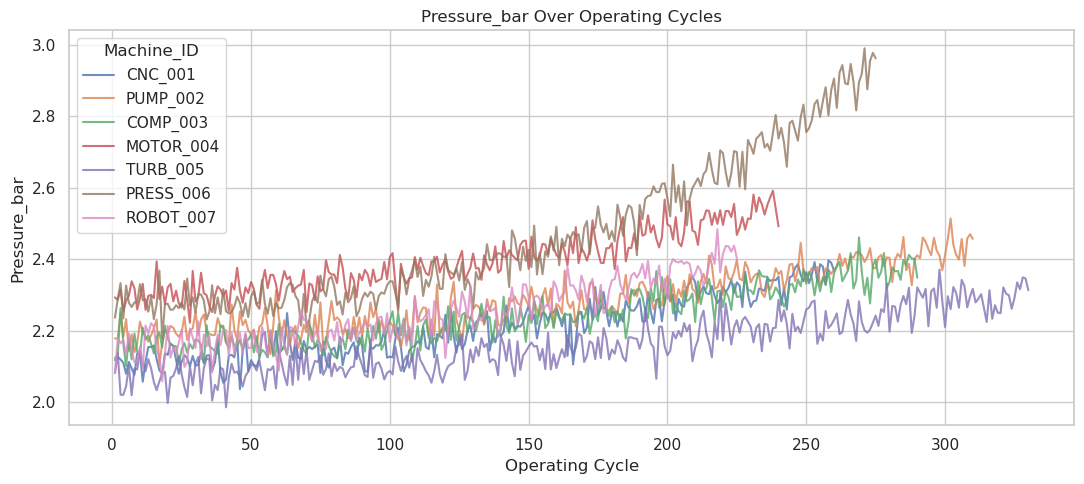

In [35]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=df,
    x="Cycle",
    y="Pressure_bar",
    hue="Machine_ID",
    alpha=0.8
)

plt.title("Pressure_bar Over Operating Cycles")
plt.xlabel("Operating Cycle")
plt.ylabel("Pressure_bar")
plt.tight_layout()
plt.show()


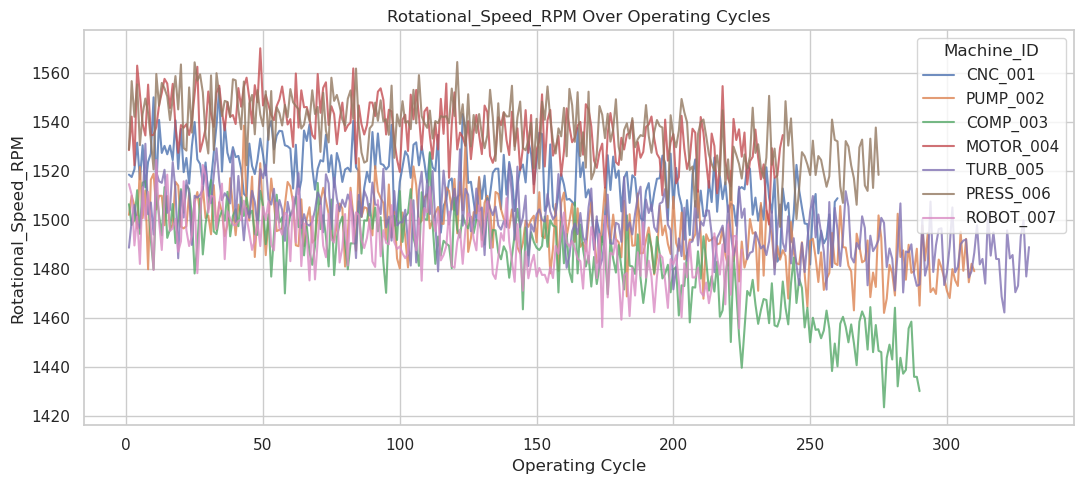

In [36]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=df,
    x="Cycle",
    y="Rotational_Speed_RPM",
    hue="Machine_ID",
    alpha=0.8
)

plt.title("Rotational_Speed_RPM Over Operating Cycles")
plt.xlabel("Operating Cycle")
plt.ylabel("Rotational_Speed_RPM")
plt.tight_layout()
plt.show()


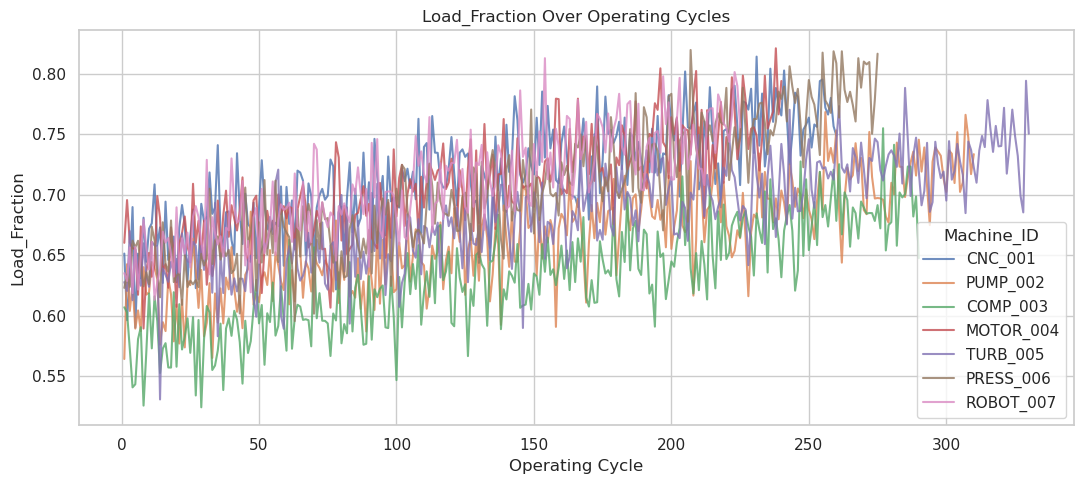

In [37]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=df,
    x="Cycle",
    y="Load_Fraction",
    hue="Machine_ID",
    alpha=0.8
)

plt.title("Load_Fraction Over Operating Cycles")
plt.xlabel("Operating Cycle")
plt.ylabel("Load_Fraction")
plt.tight_layout()
plt.show()


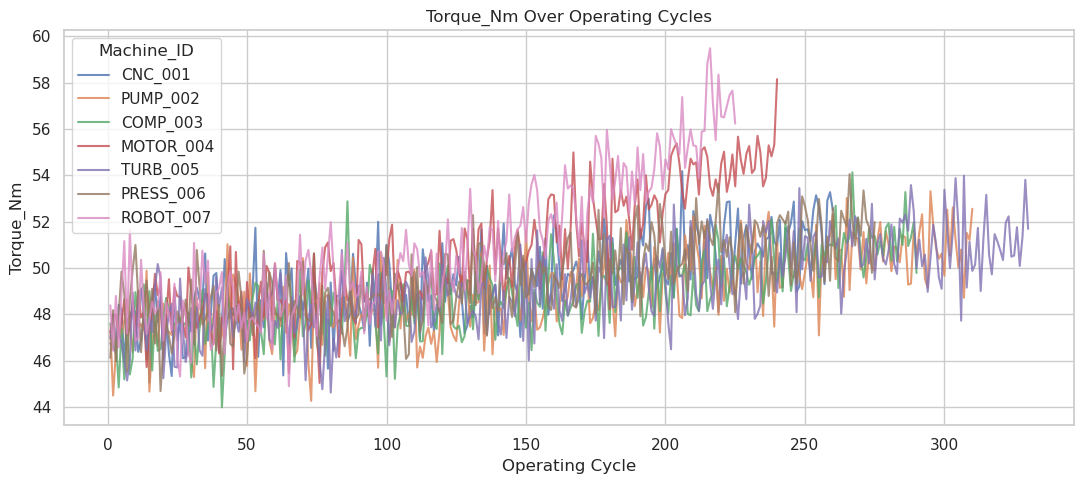

In [38]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=df,
    x="Cycle",
    y="Torque_Nm",
    hue="Machine_ID",
    alpha=0.8
)

plt.title("Torque_Nm Over Operating Cycles")
plt.xlabel("Operating Cycle")
plt.ylabel("Torque_Nm")
plt.tight_layout()
plt.show()


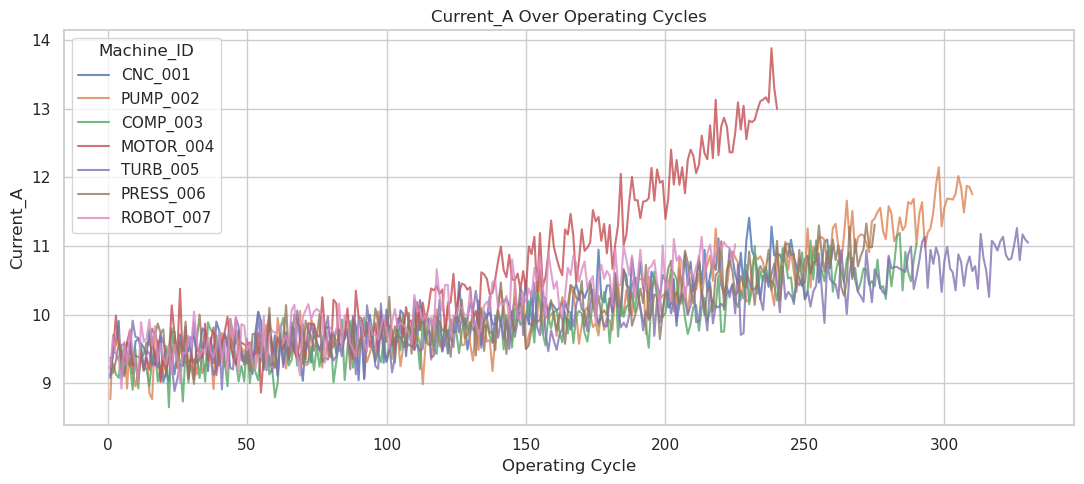

In [39]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=df,
    x="Cycle",
    y="Current_A",
    hue="Machine_ID",
    alpha=0.8
)

plt.title("Current_A Over Operating Cycles")
plt.xlabel("Operating Cycle")
plt.ylabel("Current_A")
plt.tight_layout()
plt.show()


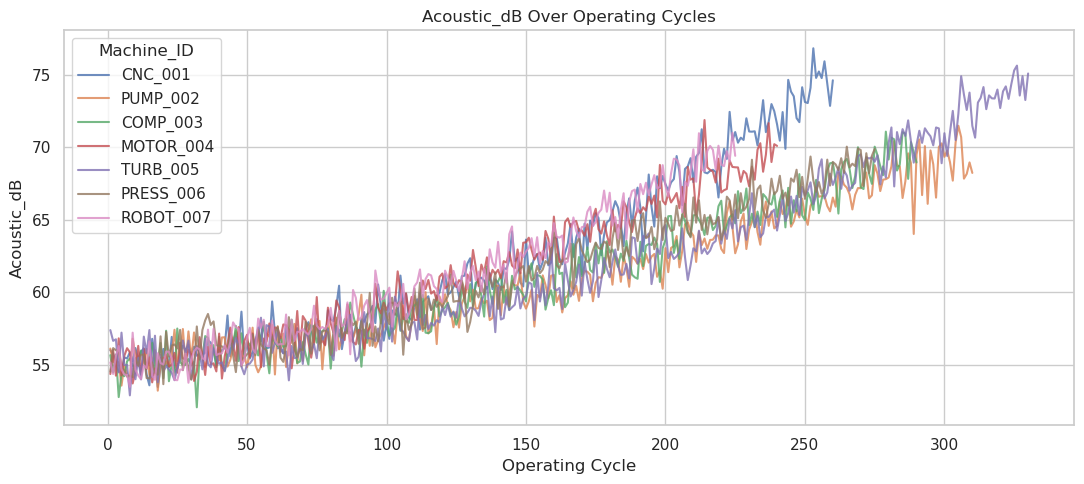

In [40]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=df,
    x="Cycle",
    y="Acoustic_dB",
    hue="Machine_ID",
    alpha=0.8
)

plt.title("Acoustic_dB Over Operating Cycles")
plt.xlabel("Operating Cycle")
plt.ylabel("Acoustic_dB")
plt.tight_layout()
plt.show()


## 15. Sensor behavior near failure

A useful predictive-maintenance question is:

> Do sensor values look different when a machine is approaching or experiencing failure?

We compare the sensor distributions for `Failure = 0` and `Failure = 1`.


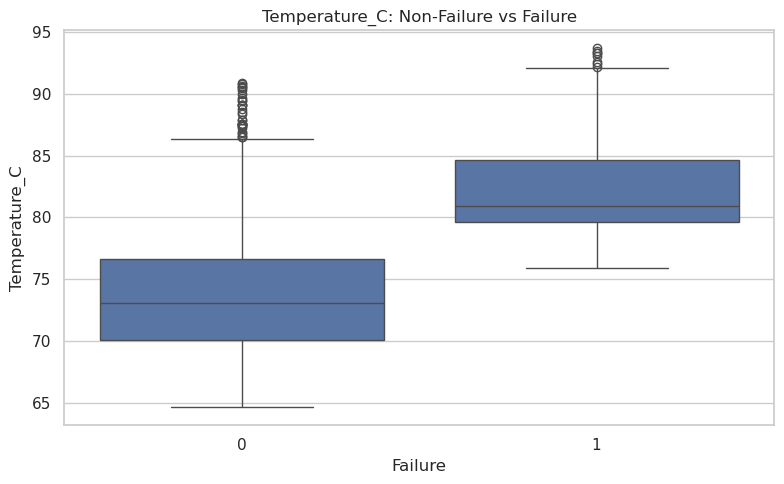

In [41]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Failure",
    y="Temperature_C"
)

plt.title("Temperature_C: Non-Failure vs Failure")
plt.xlabel("Failure")
plt.ylabel("Temperature_C")
plt.tight_layout()
plt.show()


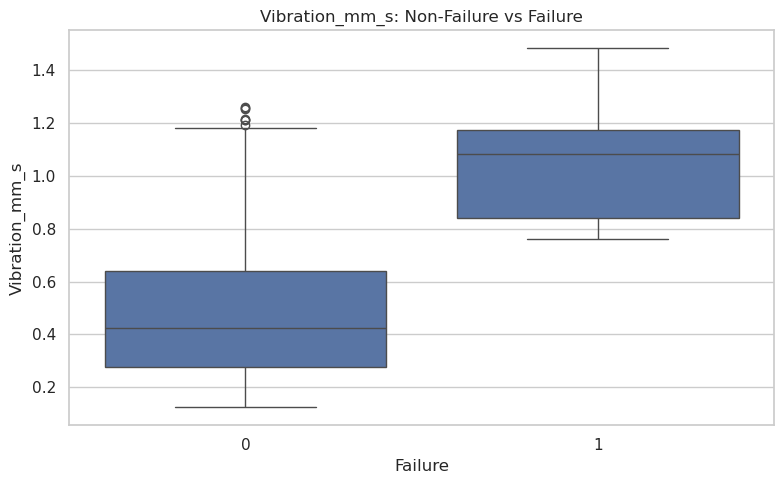

In [42]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Failure",
    y="Vibration_mm_s"
)

plt.title("Vibration_mm_s: Non-Failure vs Failure")
plt.xlabel("Failure")
plt.ylabel("Vibration_mm_s")
plt.tight_layout()
plt.show()


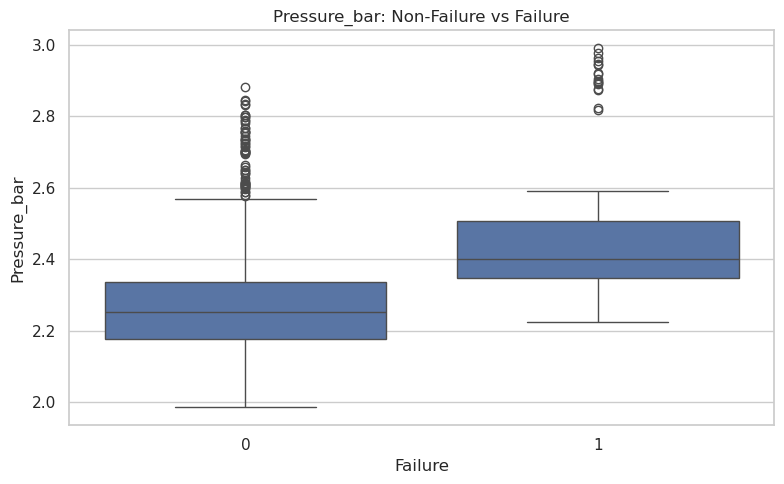

In [43]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Failure",
    y="Pressure_bar"
)

plt.title("Pressure_bar: Non-Failure vs Failure")
plt.xlabel("Failure")
plt.ylabel("Pressure_bar")
plt.tight_layout()
plt.show()


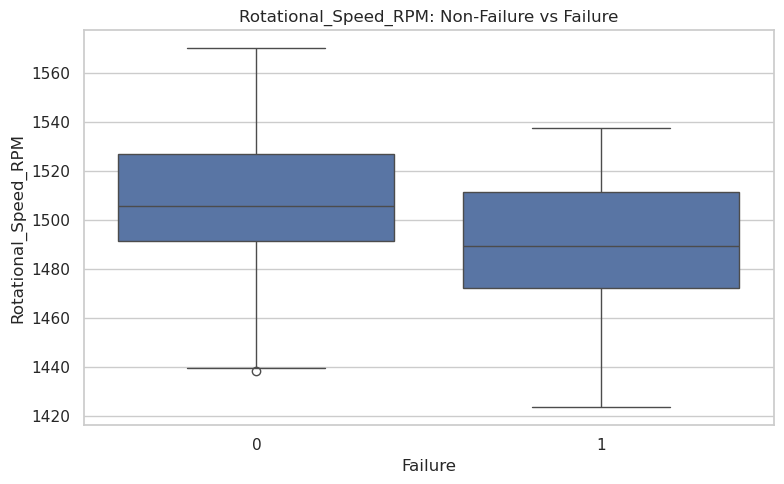

In [44]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Failure",
    y="Rotational_Speed_RPM"
)

plt.title("Rotational_Speed_RPM: Non-Failure vs Failure")
plt.xlabel("Failure")
plt.ylabel("Rotational_Speed_RPM")
plt.tight_layout()
plt.show()


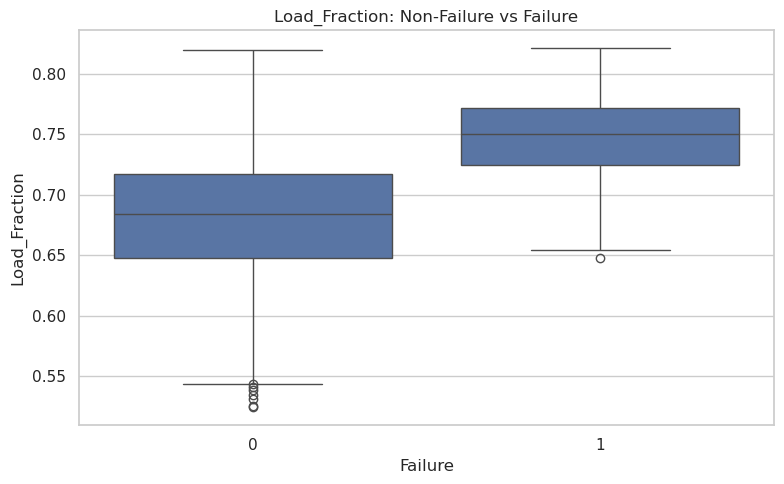

In [45]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Failure",
    y="Load_Fraction"
)

plt.title("Load_Fraction: Non-Failure vs Failure")
plt.xlabel("Failure")
plt.ylabel("Load_Fraction")
plt.tight_layout()
plt.show()


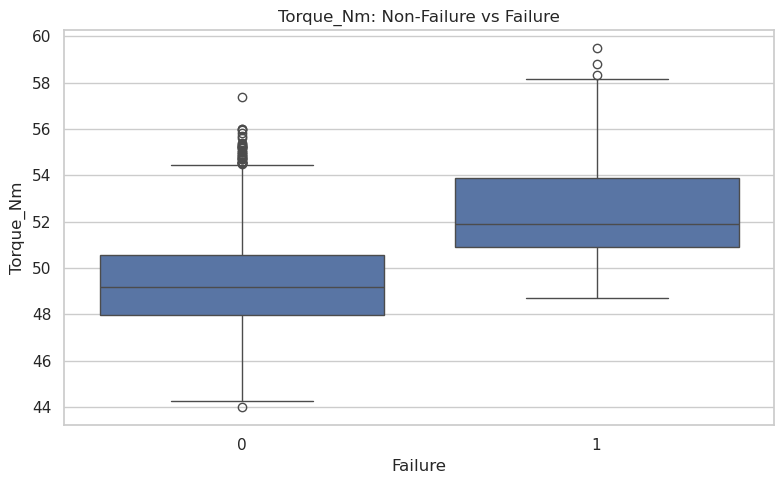

In [46]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Failure",
    y="Torque_Nm"
)

plt.title("Torque_Nm: Non-Failure vs Failure")
plt.xlabel("Failure")
plt.ylabel("Torque_Nm")
plt.tight_layout()
plt.show()


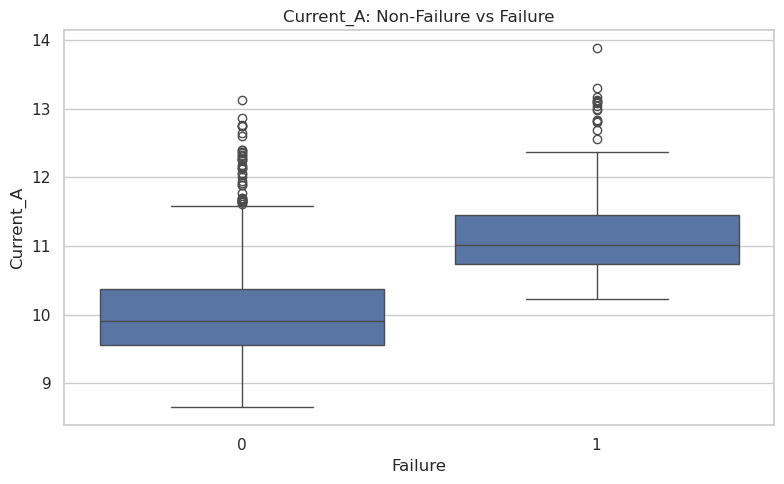

In [47]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Failure",
    y="Current_A"
)

plt.title("Current_A: Non-Failure vs Failure")
plt.xlabel("Failure")
plt.ylabel("Current_A")
plt.tight_layout()
plt.show()


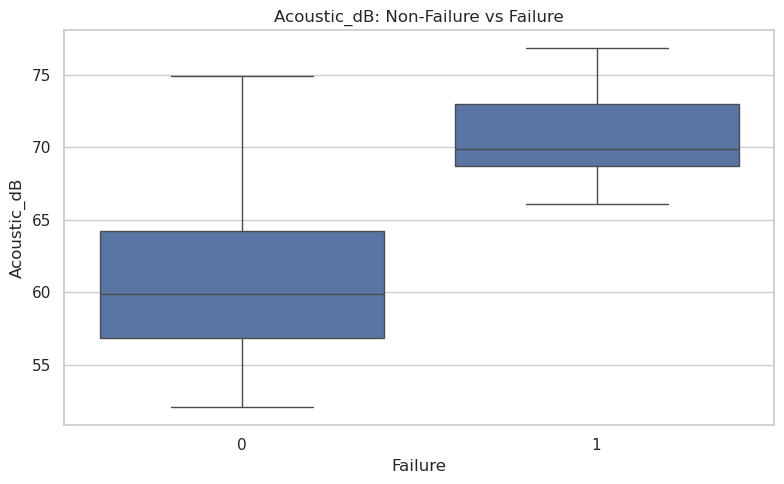

In [48]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Failure",
    y="Acoustic_dB"
)

plt.title("Acoustic_dB: Non-Failure vs Failure")
plt.xlabel("Failure")
plt.ylabel("Acoustic_dB")
plt.tight_layout()
plt.show()


## 16. Correlation analysis

Correlation is not proof of causation, but it is useful for identifying:

- strongly related sensor variables
- redundant features
- possible relationships with `Failure`
- possible relationships with `RUL_Cycles`

We include the main numeric variables.


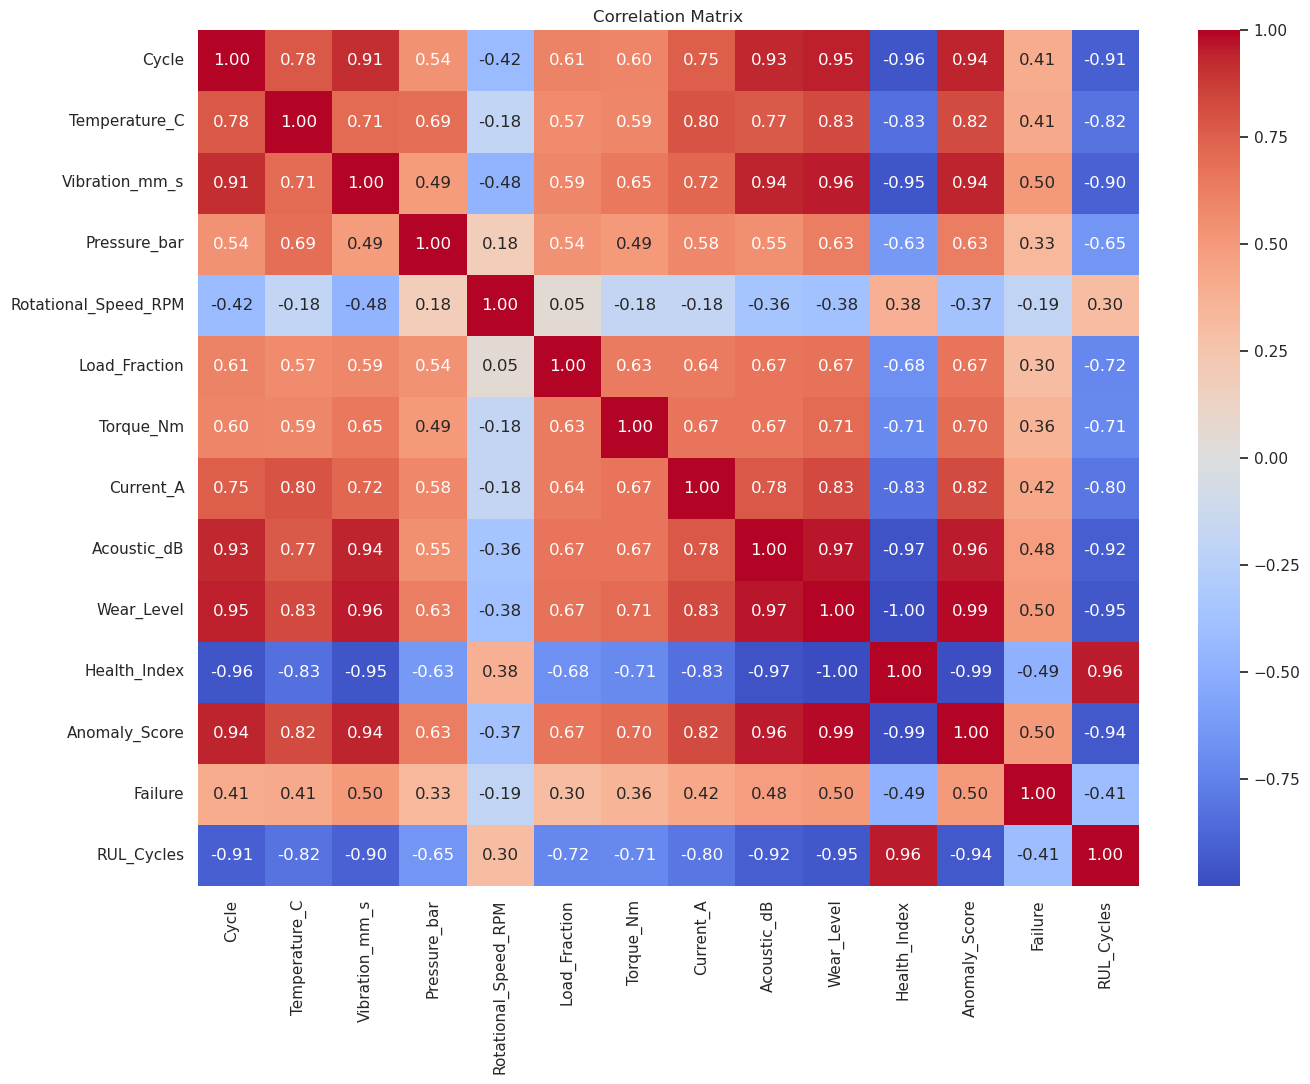

In [49]:
correlation_cols = [
    "Cycle",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Rotational_Speed_RPM",
    "Load_Fraction",
    "Torque_Nm",
    "Current_A",
    "Acoustic_dB",
    "Wear_Level",
    "Health_Index",
    "Anomaly_Score",
    "Failure",
    "RUL_Cycles",
]

corr = df[correlation_cols].corr()

plt.figure(figsize=(14, 11))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


## 17. Relationship between sensors and RUL

For predictive maintenance, we want to understand whether sensor readings contain information about remaining useful life.

Scatter plots are useful here.


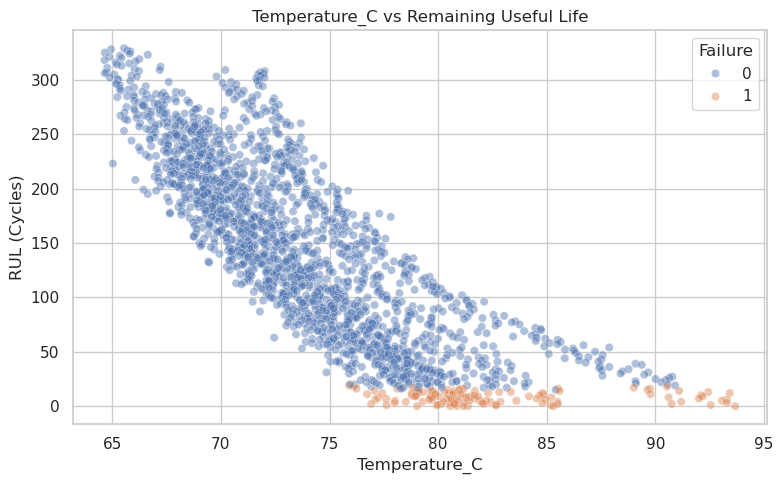

In [50]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Temperature_C",
    y="RUL_Cycles",
    hue="Failure",
    alpha=0.45
)

plt.title("Temperature_C vs Remaining Useful Life")
plt.xlabel("Temperature_C")
plt.ylabel("RUL (Cycles)")
plt.tight_layout()
plt.show()


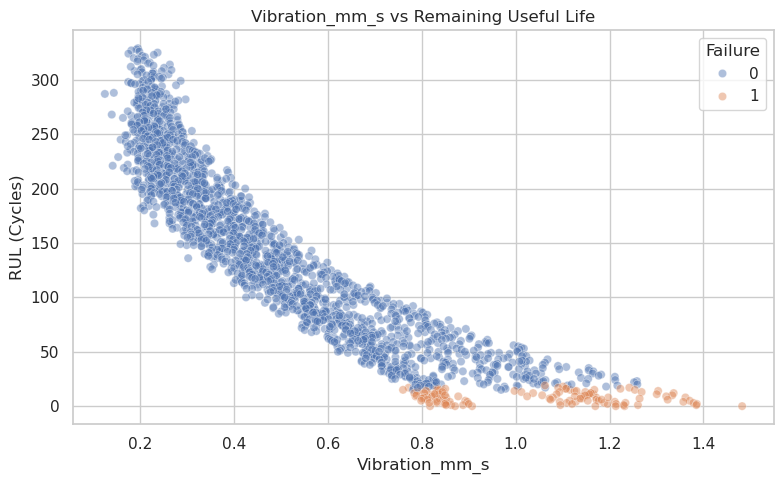

In [51]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Vibration_mm_s",
    y="RUL_Cycles",
    hue="Failure",
    alpha=0.45
)

plt.title("Vibration_mm_s vs Remaining Useful Life")
plt.xlabel("Vibration_mm_s")
plt.ylabel("RUL (Cycles)")
plt.tight_layout()
plt.show()


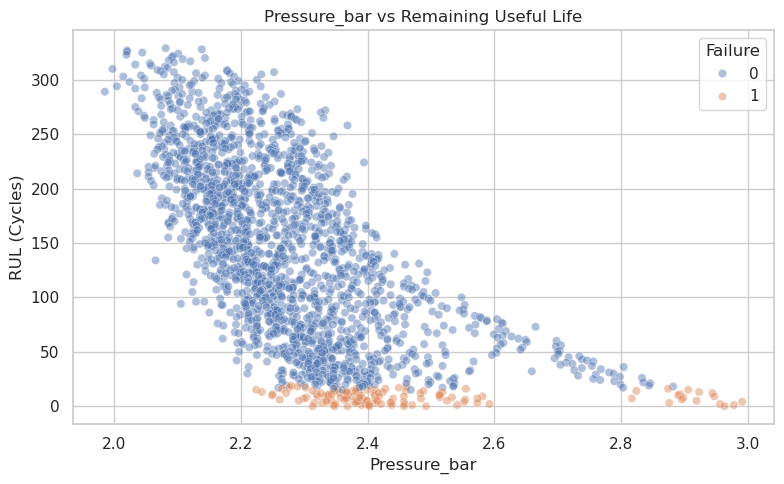

In [52]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Pressure_bar",
    y="RUL_Cycles",
    hue="Failure",
    alpha=0.45
)

plt.title("Pressure_bar vs Remaining Useful Life")
plt.xlabel("Pressure_bar")
plt.ylabel("RUL (Cycles)")
plt.tight_layout()
plt.show()


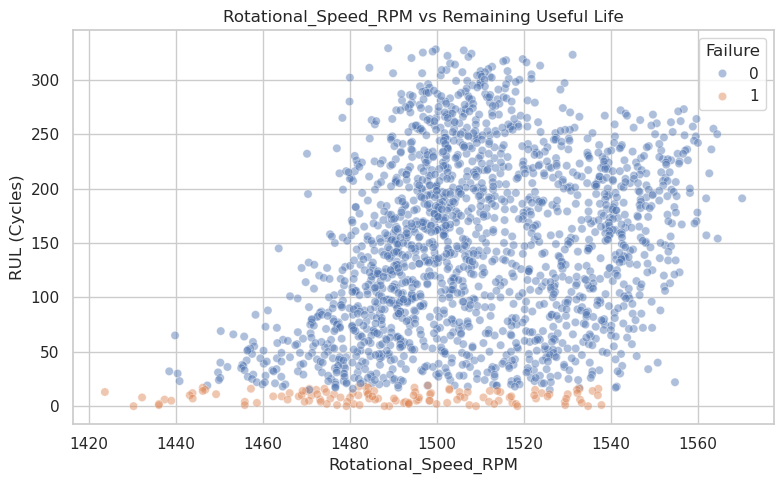

In [53]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Rotational_Speed_RPM",
    y="RUL_Cycles",
    hue="Failure",
    alpha=0.45
)

plt.title("Rotational_Speed_RPM vs Remaining Useful Life")
plt.xlabel("Rotational_Speed_RPM")
plt.ylabel("RUL (Cycles)")
plt.tight_layout()
plt.show()


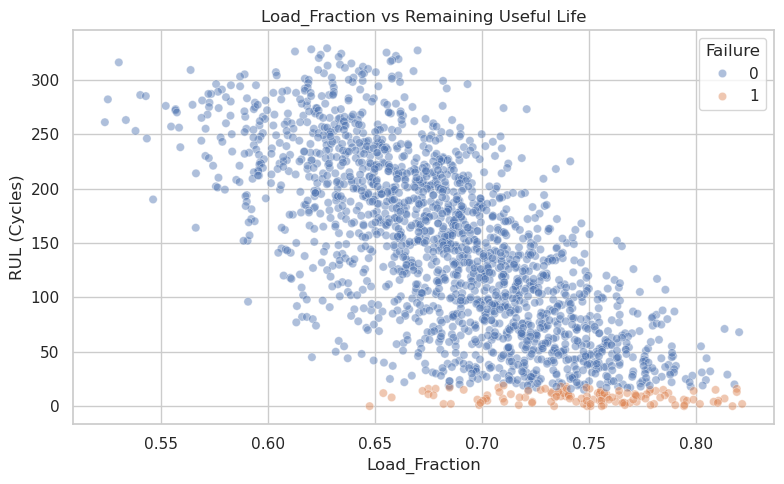

In [54]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Load_Fraction",
    y="RUL_Cycles",
    hue="Failure",
    alpha=0.45
)

plt.title("Load_Fraction vs Remaining Useful Life")
plt.xlabel("Load_Fraction")
plt.ylabel("RUL (Cycles)")
plt.tight_layout()
plt.show()


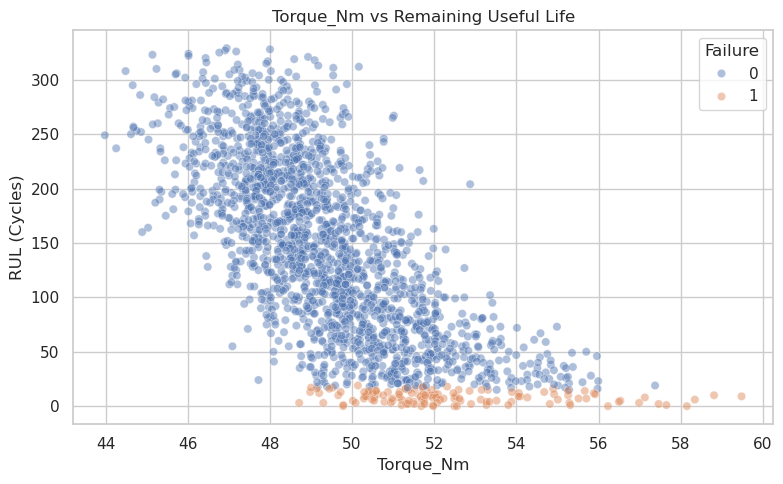

In [55]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Torque_Nm",
    y="RUL_Cycles",
    hue="Failure",
    alpha=0.45
)

plt.title("Torque_Nm vs Remaining Useful Life")
plt.xlabel("Torque_Nm")
plt.ylabel("RUL (Cycles)")
plt.tight_layout()
plt.show()


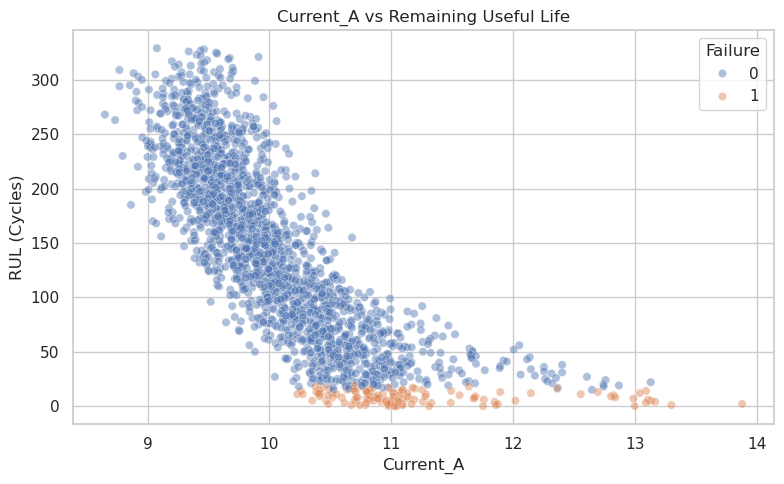

In [56]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Current_A",
    y="RUL_Cycles",
    hue="Failure",
    alpha=0.45
)

plt.title("Current_A vs Remaining Useful Life")
plt.xlabel("Current_A")
plt.ylabel("RUL (Cycles)")
plt.tight_layout()
plt.show()


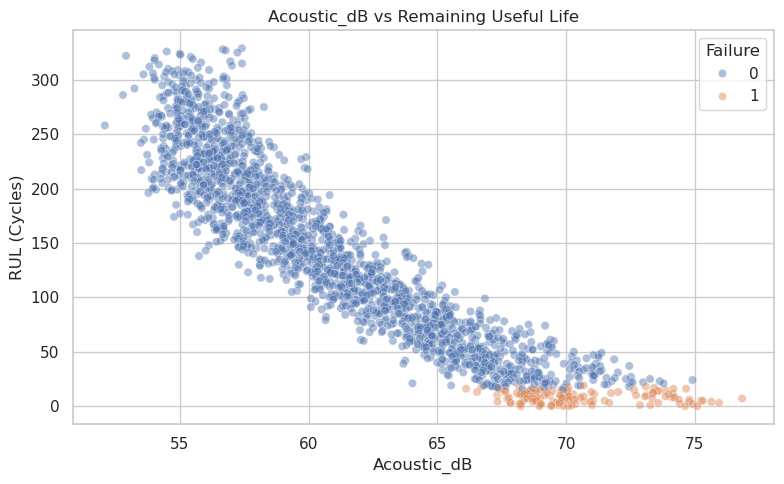

In [57]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Acoustic_dB",
    y="RUL_Cycles",
    hue="Failure",
    alpha=0.45
)

plt.title("Acoustic_dB vs Remaining Useful Life")
plt.xlabel("Acoustic_dB")
plt.ylabel("RUL (Cycles)")
plt.tight_layout()
plt.show()


## 18. Relationship between wear and health

These two variables are simulated degradation indicators. They should show a strong inverse relationship.

This is also a sanity check for the dataset generator.


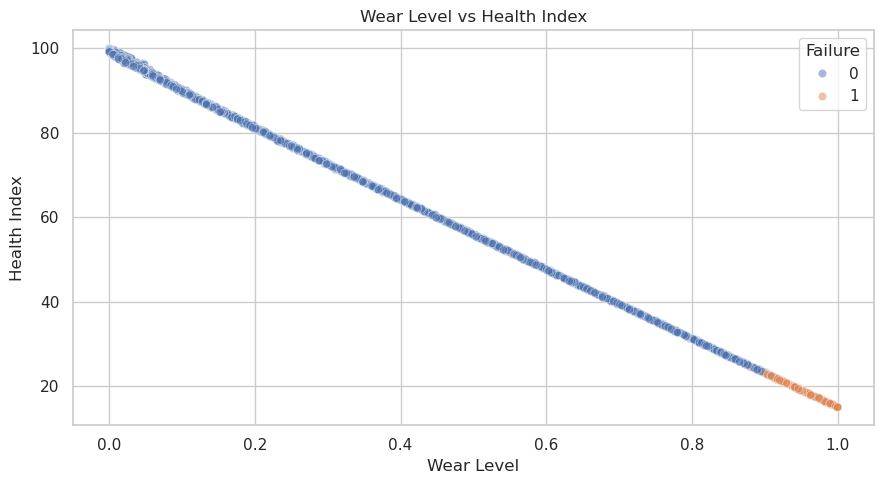

In [58]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Wear_Level",
    y="Health_Index",
    hue="Failure",
    alpha=0.5
)

plt.title("Wear Level vs Health Index")
plt.xlabel("Wear Level")
plt.ylabel("Health Index")
plt.tight_layout()
plt.show()


## 19. Relationship between wear and RUL

As wear increases, remaining useful life should generally decrease.


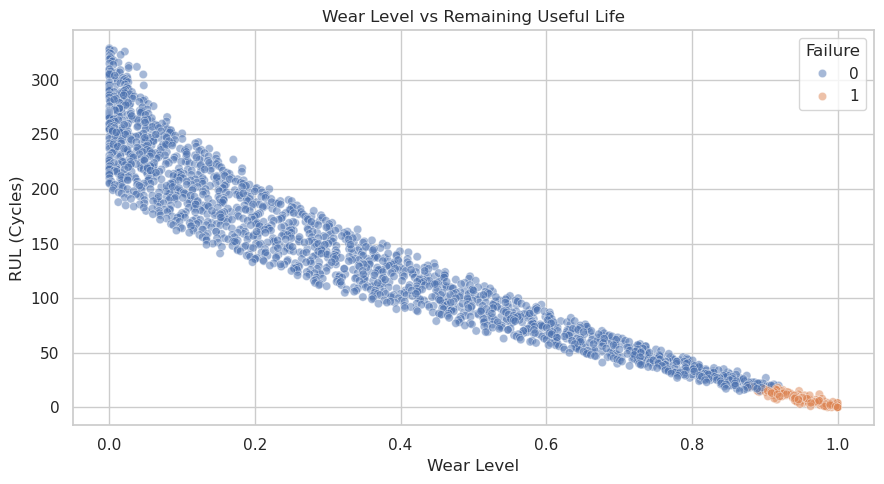

In [59]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Wear_Level",
    y="RUL_Cycles",
    hue="Failure",
    alpha=0.5
)

plt.title("Wear Level vs Remaining Useful Life")
plt.xlabel("Wear Level")
plt.ylabel("RUL (Cycles)")
plt.tight_layout()
plt.show()


## 20. Failure location within each machine's life

We want to see where failures occur relative to the machine's total operating life.

We calculate the cycle at which failure observations begin.


In [60]:
failure_start = (
    df[df["Failure"] == 1]
    .groupby("Machine_ID")["Cycle"]
    .min()
    .reset_index(name="First_Failure_Cycle")
)

machine_life = (
    df.groupby("Machine_ID")["Cycle"]
      .max()
      .reset_index(name="Total_Cycles")
)

failure_timing = failure_start.merge(machine_life, on="Machine_ID")
failure_timing["Failure_Start_%_of_Life"] = (
    failure_timing["First_Failure_Cycle"] /
    failure_timing["Total_Cycles"] * 100
).round(2)

failure_timing


,Machine_ID,First_Failure_Cycle,Total_Cycles,Failure_Start_%_of_Life
0,CNC_001,244,260,93.85
1,COMP_003,273,290,94.14
2,MOTOR_004,224,240,93.33
3,PRESS_006,259,275,94.18
4,PUMP_002,292,310,94.19
5,ROBOT_007,211,225,93.78
6,TURB_005,311,330,94.24


## 21. Check the final cycles of each machine

The final observation should represent end-of-life and therefore have:

- `Failure = 1`
- `RUL_Cycles = 0`

This is an important dataset sanity check.


In [61]:
final_rows = (
    df.sort_values(["Machine_ID", "Cycle"])
      .groupby("Machine_ID")
      .tail(1)
)

final_rows[
    [
        "Machine_ID",
        "Cycle",
        "Failure",
        "RUL_Cycles",
        "Health_Index",
        "Wear_Level"
    ]
]


,Machine_ID,Cycle,Failure,RUL_Cycles,Health_Index,Wear_Level
259,CNC_001,260,1,0,15.625,0.9917
859,COMP_003,290,1,0,15.000,1.0000
1099,MOTOR_004,240,1,0,15.000,1.0000
1704,PRESS_006,275,1,0,15.000,1.0000
569,PUMP_002,310,1,0,16.032,0.9862
1929,ROBOT_007,225,1,0,15.000,1.0000
1429,TURB_005,330,1,0,15.000,1.0000


## 22. Check time-series ordering

For every machine, cycles should increase sequentially without unexpected gaps.

This is important before building lag or rolling-window features.


In [62]:
sequence_checks = []

for machine_id, group in df.groupby("Machine_ID"):
    cycles = group.sort_values("Cycle")["Cycle"].to_numpy()
    diffs = np.diff(cycles)

    sequence_checks.append({
        "Machine_ID": machine_id,
        "Rows": len(group),
        "Min_Cycle": cycles.min(),
        "Max_Cycle": cycles.max(),
        "Sequential": np.all(diffs == 1),
        "Missing_Cycle_Count": int(np.sum(diffs != 1)),
    })

sequence_check_df = pd.DataFrame(sequence_checks)
sequence_check_df


,Machine_ID,Rows,Min_Cycle,Max_Cycle,Sequential,Missing_Cycle_Count
0,CNC_001,260,1,260,True,0
1,COMP_003,290,1,290,True,0
2,MOTOR_004,240,1,240,True,0
3,PRESS_006,275,1,275,True,0
4,PUMP_002,310,1,310,True,0
5,ROBOT_007,225,1,225,True,0
6,TURB_005,330,1,330,True,0


## 23. Potential data leakage — IMPORTANT

Before training, we must distinguish between **features that would realistically be available before prediction** and variables that directly reveal the target or future information.

### Examples

`Failure`:
- This is our target for classification.
- **Do not use it as an input feature.**

`RUL_Cycles`:
- This is the target for RUL regression.
- **Do not use it as an input feature when predicting RUL.**

`Health_Index`, `Wear_Level`, and `Anomaly_Score`:
- In this synthetic dataset they were generated from the underlying degradation process.
- They may be useful as features **only if we treat them as observable machine-state measurements**.
- If they are calculated using future information, they would create leakage.

For the first ML model, we should therefore be conservative and start with the raw sensor measurements plus carefully constructed historical features.


## 24. Candidate modeling columns

We now explicitly separate:

- identifiers
- categorical descriptors
- raw sensor features
- targets

This is preparation for the next notebook/modeling stage.


In [63]:
id_cols = [
    "Machine_ID",
    "Machine_Type",
    "Failure_Mode",
]

target_cols = [
    "Failure",
    "RUL_Cycles",
]

derived_state_cols = [
    "Wear_Level",
    "Health_Index",
    "Anomaly_Score",
]

sensor_cols


['Temperature_C',
 'Vibration_mm_s',
 'Pressure_bar',
 'Rotational_Speed_RPM',
 'Load_Fraction',
 'Torque_Nm',
 'Current_A',
 'Acoustic_dB']

In [64]:
print("Identifier / categorical columns:")
print(id_cols)

print("\nRaw sensor columns:")
print(sensor_cols)

print("\nTargets:")
print(target_cols)

print("\nDerived state columns requiring leakage consideration:")
print(derived_state_cols)


Identifier / categorical columns:
['Machine_ID', 'Machine_Type', 'Failure_Mode']

Raw sensor columns:
['Temperature_C', 'Vibration_mm_s', 'Pressure_bar', 'Rotational_Speed_RPM', 'Load_Fraction', 'Torque_Nm', 'Current_A', 'Acoustic_dB']

Targets:
['Failure', 'RUL_Cycles']

Derived state columns requiring leakage consideration:
['Wear_Level', 'Health_Index', 'Anomaly_Score']


## 25. Key EDA conclusions

Run this cell after completing the notebook to produce a compact automatic summary.


In [65]:
print("========== SMART TWIN EDA SUMMARY ==========")
print(f"Total observations: {len(df):,}")
print(f"Number of machines: {df['Machine_ID'].nunique()}")
print(f"Number of machine types: {df['Machine_Type'].nunique()}")
print(f"Number of failure modes: {df['Failure_Mode'].nunique()}")
print(f"Missing values: {int(df.isna().sum().sum())}")
print(f"Duplicate rows: {int(df.duplicated().sum())}")
print(f"Failure observations: {int(df['Failure'].sum()):,}")
print(f"Failure rate: {df['Failure'].mean()*100:.2f}%")
print(f"Minimum RUL: {df['RUL_Cycles'].min()}")
print(f"Maximum RUL: {df['RUL_Cycles'].max()}")
print("=============================================")


========== SMART TWIN EDA SUMMARY ==========
Total observations: 1,930
Number of machines: 7
Number of machine types: 7
Number of failure modes: 6
Missing values: 0
Duplicate rows: 0
Failure observations: 122
Failure rate: 6.32%
Minimum RUL: 0
Maximum RUL: 329


# Next stage — Model development

After reviewing this EDA, the next stage should **not** be to blindly call `.fit()`.

We will first decide the modeling formulation.

## Model A — Failure classification

Question:

> Given the machine's current and recent sensor history, will it fail?

Target:

```text
Failure
```

Potential models:

1. Logistic Regression — baseline
2. Random Forest
3. Gradient Boosting / HistGradientBoosting
4. XGBoost/LightGBM if we decide to add them

## Model B — Remaining Useful Life regression

Question:

> How many cycles does the machine have remaining?

Target:

```text
RUL_Cycles
```

Potential models:

1. Linear Regression — baseline
2. Random Forest Regressor
3. Gradient Boosting Regressor
4. Sequence model such as LSTM/GRU later

## Critical time-series consideration

We should split data by **machine**, not randomly by individual rows.

For example:

```text
Training machines
    CNC_001
    PUMP_002
    COMP_003
    MOTOR_004

Validation machines
    TURB_005

Test machines
    PRESS_006
    ROBOT_007
```

This prevents observations from the same machine appearing in both training and test sets.

Only after this split will we create historical features such as:

- lag values
- rolling mean
- rolling standard deviation
- rate of change
- recent sensor window

That will give us a much more realistic predictive-maintenance model.
